# Notebook 02 — Churn Distribution Analysis
# Organization: European Banking | Unified Mentor Internship
# Author: [Rishi Prajapati] 

## Objective
Deep-dive churn analysis by segments, demographics,
and financial profiles. Calculate all 5 KPIs.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
import os
import warnings

warnings.filterwarnings('ignore')
plt.rcParams['figure.figsize'] = (13, 6)
plt.rcParams['font.size']      = 12
sns.set_style('whitegrid')
os.makedirs('../reports/figures', exist_ok=True)

# Load segmented data
df = pd.read_csv('../data/processed/churn_segmented.csv')

print("✅ Data loaded!")
print(f"   Shape: {df.shape}")
print(f"   Churn Rate: {df['Exited'].mean():.2%}")
df.head(3)

✅ Data loaded!
   Shape: (10000, 16)
   Churn Rate: 20.37%


,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,age_segment,credit_band,tenure_group,balance_segment,products_segment
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1,30-45,Medium,New (0-2 yrs),Zero Balance,1 Product
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0,30-45,Medium,New (0-2 yrs),Low Balance,1 Product
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,1,30-45,Low,Long-term (7+ yrs),High Balance,3+ Products


## Segment-wise Churn Rates

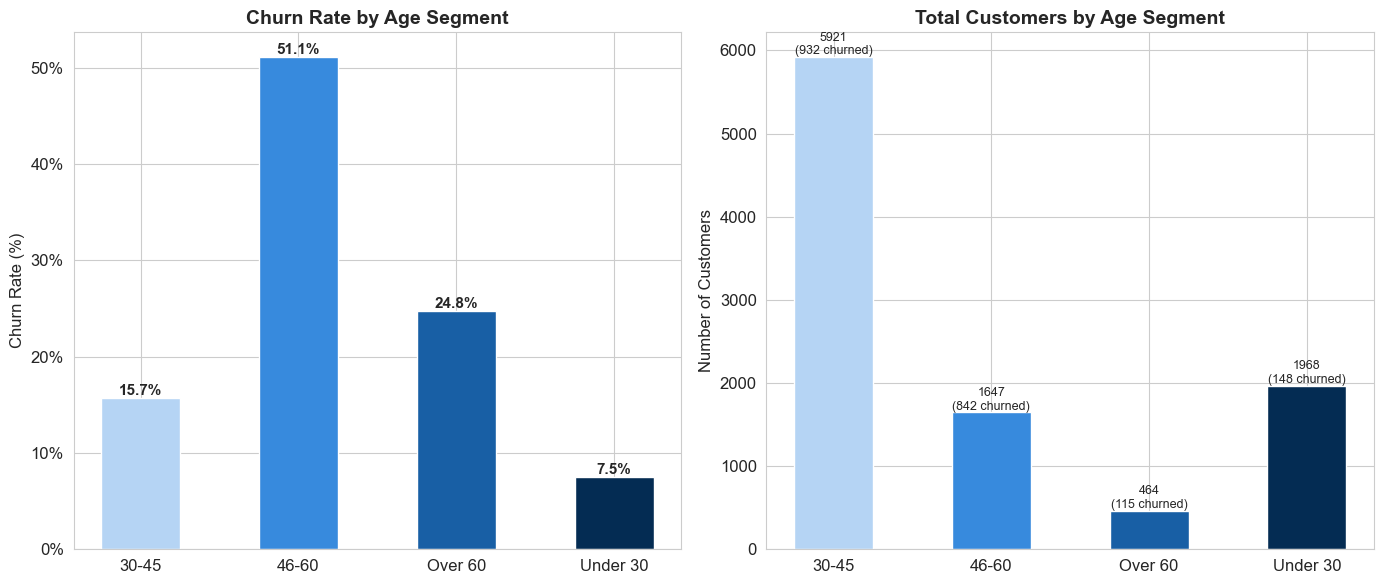


📌 Age Segment Summary:
 Segment  Churned  Total  ChurnRate  ChurnRate_pct
   30-45      932   5921   0.157406      15.740584
   46-60      842   1647   0.511233      51.123254
 Over 60      115    464   0.247845      24.784483
Under 30      148   1968   0.075203       7.520325


In [2]:
# ── Chart 7: Age Segment Churn Rate ──────────────────────────────
age_churn = df.groupby('age_segment', observed=True)['Exited']\
              .agg(['sum','count','mean']).reset_index()
age_churn.columns = ['Segment', 'Churned', 'Total', 'ChurnRate']
age_churn['ChurnRate_pct'] = age_churn['ChurnRate'] * 100

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
colors = ['#B5D4F4', '#378ADD', '#185FA5', '#042C53']

axes[0].bar(age_churn['Segment'], age_churn['ChurnRate_pct'],
            color=colors, edgecolor='white', width=0.5)
axes[0].set_title('Churn Rate by Age Segment', fontsize=14, fontweight='bold')
axes[0].set_ylabel('Churn Rate (%)')
axes[0].yaxis.set_major_formatter(mtick.PercentFormatter())
for i, row in age_churn.iterrows():
    axes[0].text(i, row['ChurnRate_pct'] + 0.3,
                 f"{row['ChurnRate_pct']:.1f}%",
                 ha='center', fontsize=11, fontweight='bold')

axes[1].bar(age_churn['Segment'], age_churn['Total'],
            color=colors, edgecolor='white', width=0.5)
axes[1].set_title('Total Customers by Age Segment', fontsize=14, fontweight='bold')
axes[1].set_ylabel('Number of Customers')
for i, row in age_churn.iterrows():
    axes[1].text(i, row['Total'] + 30,
                 f"{row['Total']}\n({row['Churned']} churned)",
                 ha='center', fontsize=9)

plt.tight_layout()
plt.savefig('../reports/figures/07_age_segment_churn.png', dpi=150, bbox_inches='tight')
plt.show()
print("\n📌 Age Segment Summary:")
print(age_churn.to_string(index=False))

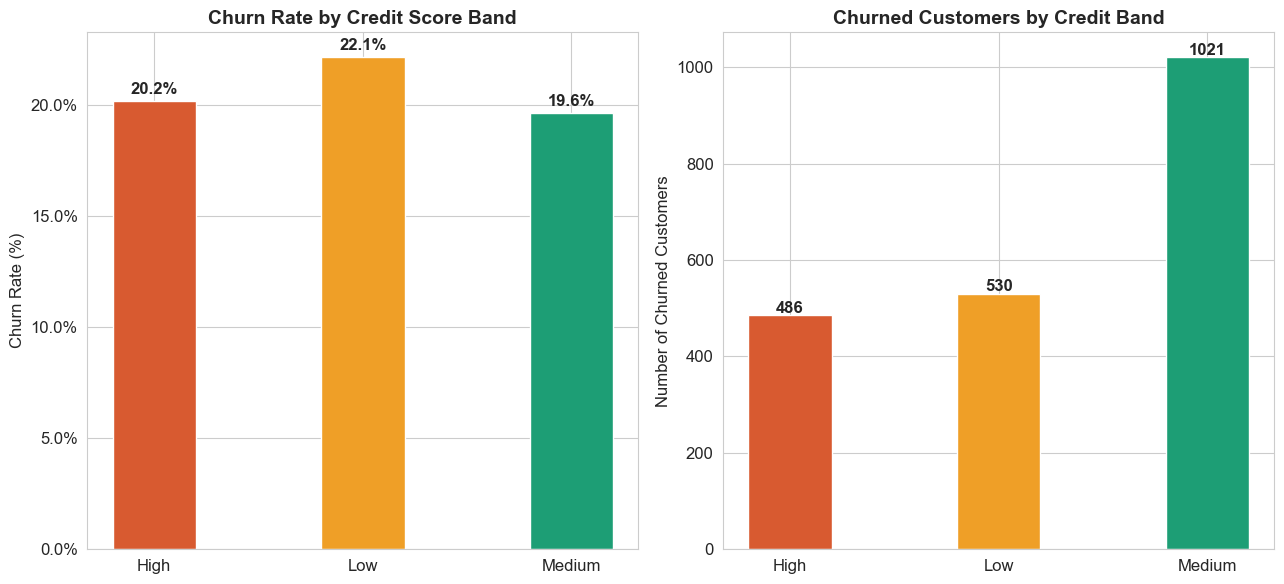

In [3]:
# ── Chart 8: Credit Score Band Churn ─────────────────────────────
credit_churn = df.groupby('credit_band', observed=True)['Exited']\
                 .agg(['sum','count','mean']).reset_index()
credit_churn.columns = ['CreditBand', 'Churned', 'Total', 'ChurnRate']

fig, axes = plt.subplots(1, 2, figsize=(13, 6))
c_colors = ['#D85A30', '#EF9F27', '#1D9E75']

axes[0].bar(credit_churn['CreditBand'], credit_churn['ChurnRate']*100,
            color=c_colors, edgecolor='white', width=0.4)
axes[0].set_title('Churn Rate by Credit Score Band', fontsize=14, fontweight='bold')
axes[0].set_ylabel('Churn Rate (%)')
axes[0].yaxis.set_major_formatter(mtick.PercentFormatter())
for i, row in credit_churn.iterrows():
    axes[0].text(i, row['ChurnRate']*100 + 0.3,
                 f"{row['ChurnRate']*100:.1f}%",
                 ha='center', fontsize=12, fontweight='bold')

axes[1].bar(credit_churn['CreditBand'], credit_churn['Churned'],
            color=c_colors, edgecolor='white', width=0.4)
axes[1].set_title('Churned Customers by Credit Band', fontsize=14, fontweight='bold')
axes[1].set_ylabel('Number of Churned Customers')
for i, row in credit_churn.iterrows():
    axes[1].text(i, row['Churned'] + 5, str(row['Churned']),
                 ha='center', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.savefig('../reports/figures/08_credit_band_churn.png', dpi=150, bbox_inches='tight')
plt.show()


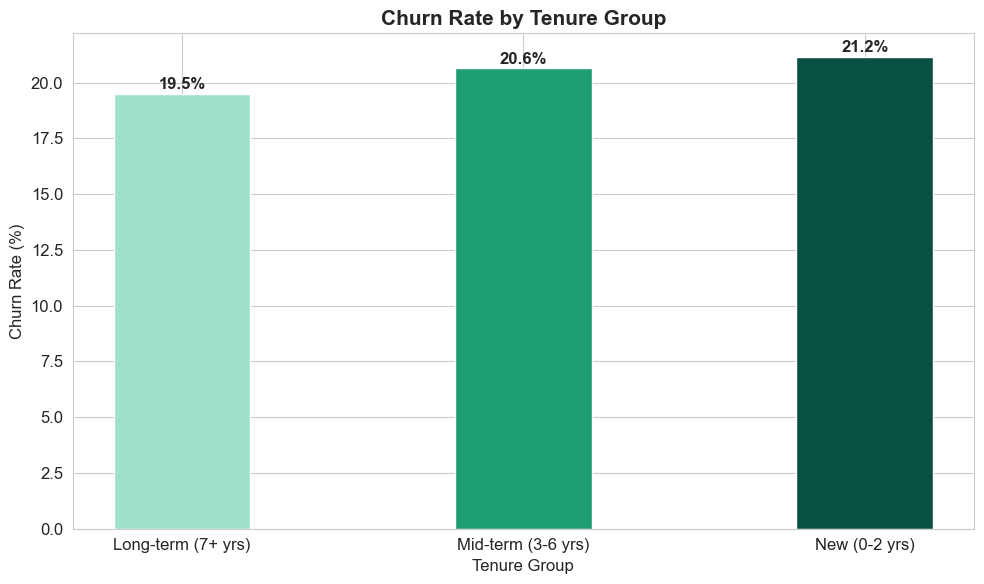


📌 Tenure Group Summary:
       TenureGroup  Churned  Total  ChurnRate
Long-term (7+ yrs)      688   3527   0.195067
Mid-term (3-6 yrs)      821   3977   0.206437
     New (0-2 yrs)      528   2496   0.211538


In [4]:
# ── Chart 9: Tenure Group Churn ───────────────────────────────────
tenure_churn = df.groupby('tenure_group', observed=True)['Exited']\
                 .agg(['sum','count','mean']).reset_index()
tenure_churn.columns = ['TenureGroup', 'Churned', 'Total', 'ChurnRate']

plt.figure(figsize=(10, 6))
t_colors = ['#9FE1CB', '#1D9E75', '#085041']
bars = plt.bar(tenure_churn['TenureGroup'], tenure_churn['ChurnRate']*100,
               color=t_colors, edgecolor='white', width=0.4)
plt.title('Churn Rate by Tenure Group', fontsize=15, fontweight='bold')
plt.ylabel('Churn Rate (%)')
plt.xlabel('Tenure Group')
plt.yaxis_formatter = mtick.PercentFormatter()
for bar, val in zip(bars, tenure_churn['ChurnRate']*100):
    plt.text(bar.get_x() + bar.get_width()/2,
             bar.get_height() + 0.2,
             f"{val:.1f}%", ha='center', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('../reports/figures/09_tenure_churn.png', dpi=150, bbox_inches='tight')
plt.show()

print("\n📌 Tenure Group Summary:")
print(tenure_churn.to_string(index=False))

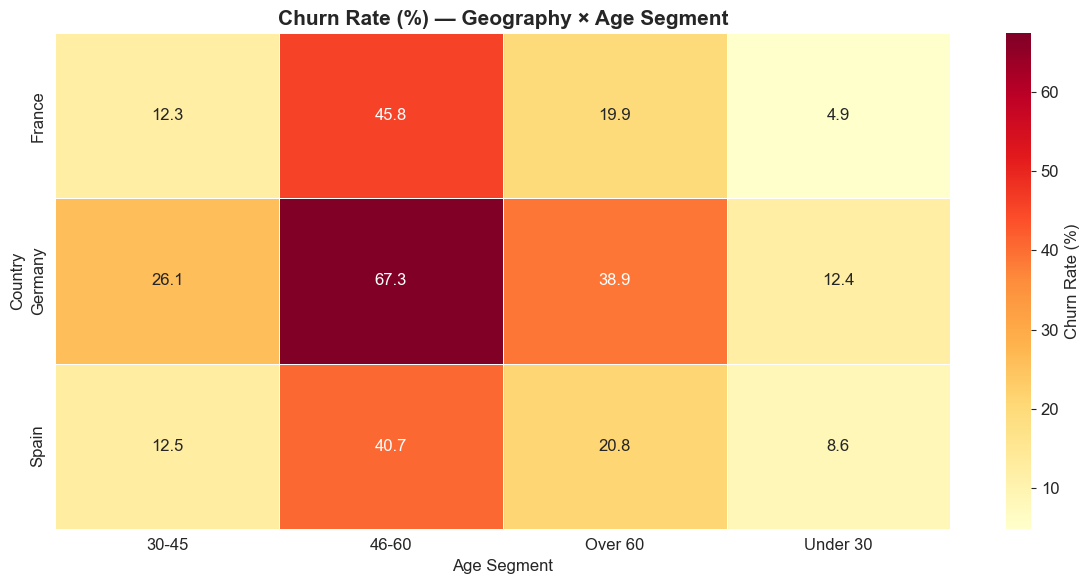


📌 Geography × Age Cross-Analysis (Churn Rate %):
age_segment  30-45  46-60  Over 60  Under 30
Geography                                   
France        12.3   45.8     19.9       4.9
Germany       26.1   67.3     38.9      12.4
Spain         12.5   40.7     20.8       8.6


In [5]:
# ── Chart 10: Geography × Age Segment Heatmap ────────────────────
geo_age = df.groupby(['Geography', 'age_segment'], observed=True)['Exited']\
            .mean().unstack() * 100

plt.figure(figsize=(12, 6))
sns.heatmap(
    geo_age,
    annot      = True,
    fmt        = '.1f',
    cmap       = 'YlOrRd',
    linewidths = 0.5,
    cbar_kws   = {'label': 'Churn Rate (%)'}
)
plt.title('Churn Rate (%) — Geography × Age Segment', fontsize=15, fontweight='bold')
plt.xlabel('Age Segment')
plt.ylabel('Country')
plt.tight_layout()
plt.savefig('../reports/figures/10_geo_age_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

print("\n📌 Geography × Age Cross-Analysis (Churn Rate %):")
print(geo_age.round(1).to_string())

## Demographic & Financial Analysis

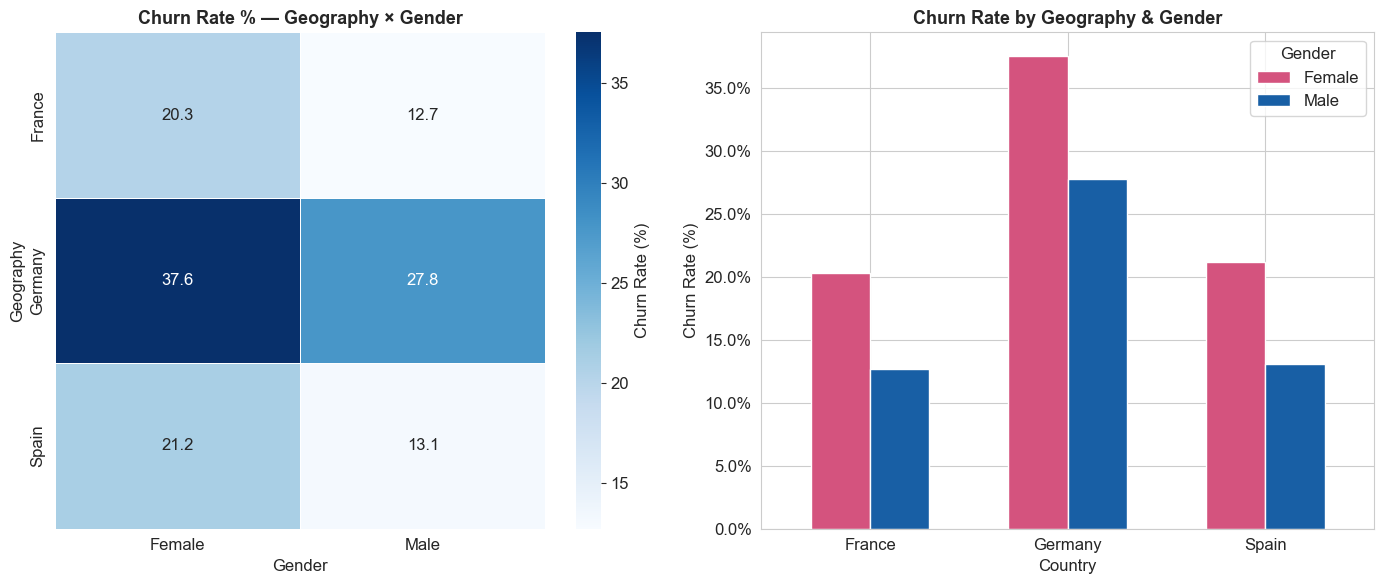

In [6]:
# ── Chart 11: Gender × Geography Churn Matrix ────────────────────
gender_geo = df.groupby(['Geography', 'Gender'])['Exited']\
               .mean().unstack() * 100

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Heatmap
sns.heatmap(gender_geo, annot=True, fmt='.1f', cmap='Blues',
            linewidths=0.5, ax=axes[0], cbar_kws={'label':'Churn Rate (%)'})
axes[0].set_title('Churn Rate % — Geography × Gender', fontsize=13, fontweight='bold')

# Grouped bar chart
gender_geo.plot(kind='bar', ax=axes[1], color=['#D4537E', '#185FA5'],
                edgecolor='white', width=0.6)
axes[1].set_title('Churn Rate by Geography & Gender', fontsize=13, fontweight='bold')
axes[1].set_ylabel('Churn Rate (%)')
axes[1].set_xlabel('Country')
axes[1].legend(title='Gender')
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter())
plt.xticks(rotation=0)

plt.tight_layout()
plt.savefig('../reports/figures/11_gender_geo_churn.png', dpi=150, bbox_inches='tight')
plt.show()

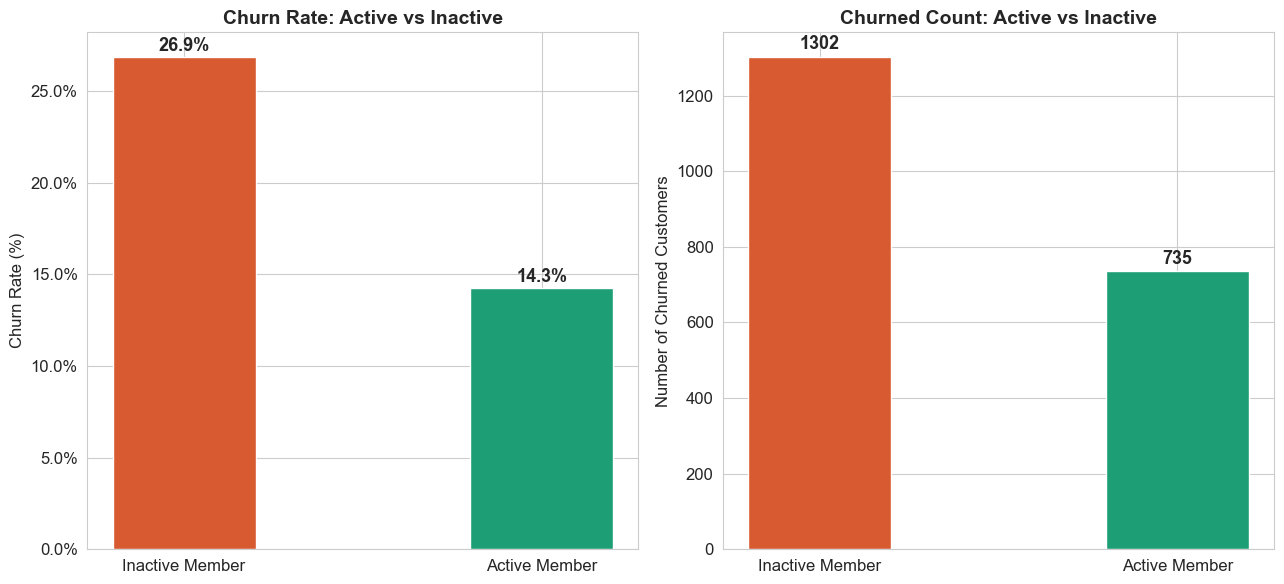


📌 Engagement Drop Indicator (KPI 5):
          Label  sum  count     mean
Inactive Member 1302   4849 0.268509
  Active Member  735   5151 0.142691


In [7]:
# ── Chart 12: Active vs Inactive Member Churn ────────────────────
active_churn = df.groupby('IsActiveMember')['Exited']\
                 .agg(['sum','count','mean']).reset_index()
active_churn['Label'] = active_churn['IsActiveMember'].map(
    {0: 'Inactive Member', 1: 'Active Member'})

fig, axes = plt.subplots(1, 2, figsize=(13, 6))
a_colors = ['#D85A30', '#1D9E75']

axes[0].bar(active_churn['Label'], active_churn['mean']*100,
            color=a_colors, edgecolor='white', width=0.4)
axes[0].set_title('Churn Rate: Active vs Inactive', fontsize=14, fontweight='bold')
axes[0].set_ylabel('Churn Rate (%)')
axes[0].yaxis.set_major_formatter(mtick.PercentFormatter())
for i, row in active_churn.iterrows():
    axes[0].text(i, row['mean']*100 + 0.3,
                 f"{row['mean']*100:.1f}%",
                 ha='center', fontsize=13, fontweight='bold')

axes[1].bar(active_churn['Label'], active_churn['sum'],
            color=a_colors, edgecolor='white', width=0.4)
axes[1].set_title('Churned Count: Active vs Inactive', fontsize=14, fontweight='bold')
axes[1].set_ylabel('Number of Churned Customers')
for i, row in active_churn.iterrows():
    axes[1].text(i, row['sum'] + 20, str(row['sum']),
                 ha='center', fontsize=13, fontweight='bold')

plt.tight_layout()
plt.savefig('../reports/figures/12_active_member_churn.png', dpi=150, bbox_inches='tight')
plt.show()

print("\n📌 Engagement Drop Indicator (KPI 5):")
print(active_churn[['Label','sum','count','mean']].to_string(index=False))

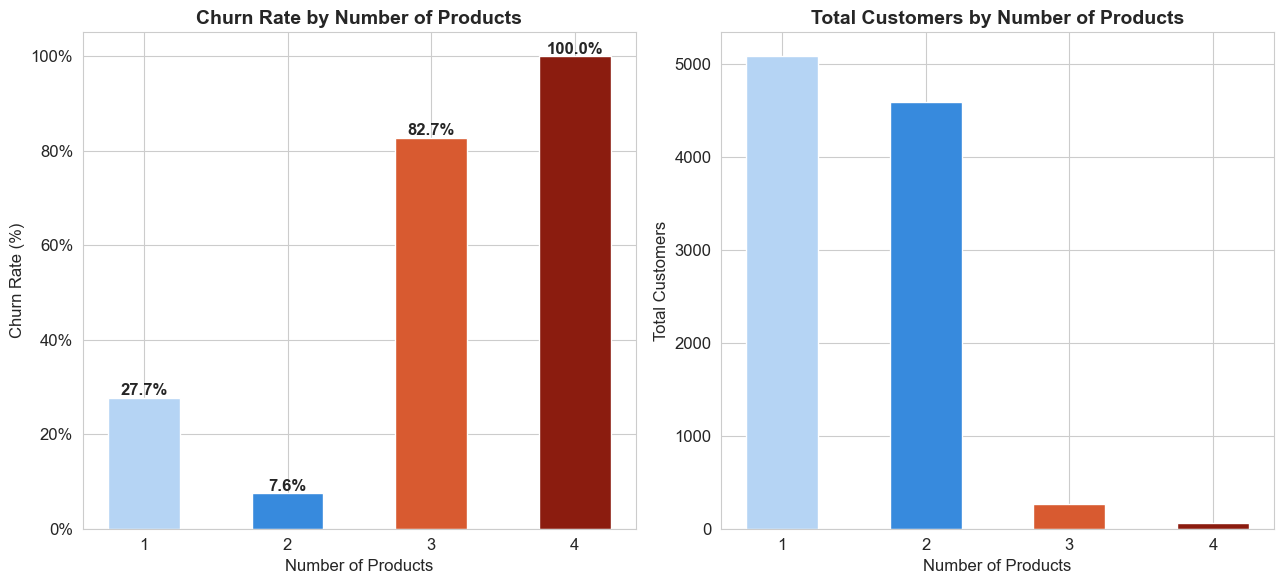


📌 Key Insight — Products vs Churn:
 NumProducts  Churned  Total  ChurnRate
           1     1409   5084   0.277144
           2      348   4590   0.075817
           3      220    266   0.827068
           4       60     60   1.000000


In [8]:
# ── Chart 13: NumOfProducts vs Churn ─────────────────────────────
products_churn = df.groupby('NumOfProducts')['Exited']\
                   .agg(['sum','count','mean']).reset_index()
products_churn.columns = ['NumProducts', 'Churned', 'Total', 'ChurnRate']

fig, axes = plt.subplots(1, 2, figsize=(13, 6))
p_colors = ['#B5D4F4', '#378ADD', '#D85A30', '#8B1C0F']

axes[0].bar(products_churn['NumProducts'].astype(str),
            products_churn['ChurnRate']*100,
            color=p_colors[:len(products_churn)], edgecolor='white', width=0.5)
axes[0].set_title('Churn Rate by Number of Products', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Number of Products')
axes[0].set_ylabel('Churn Rate (%)')
axes[0].yaxis.set_major_formatter(mtick.PercentFormatter())
for i, row in products_churn.iterrows():
    axes[0].text(i, row['ChurnRate']*100 + 0.5,
                 f"{row['ChurnRate']*100:.1f}%",
                 ha='center', fontsize=12, fontweight='bold')

axes[1].bar(products_churn['NumProducts'].astype(str),
            products_churn['Total'],
            color=p_colors[:len(products_churn)], edgecolor='white', width=0.5)
axes[1].set_title('Total Customers by Number of Products', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Number of Products')
axes[1].set_ylabel('Total Customers')

plt.tight_layout()
plt.savefig('../reports/figures/13_products_churn.png', dpi=150, bbox_inches='tight')
plt.show()

print("\n📌 Key Insight — Products vs Churn:")
print(products_churn.to_string(index=False))

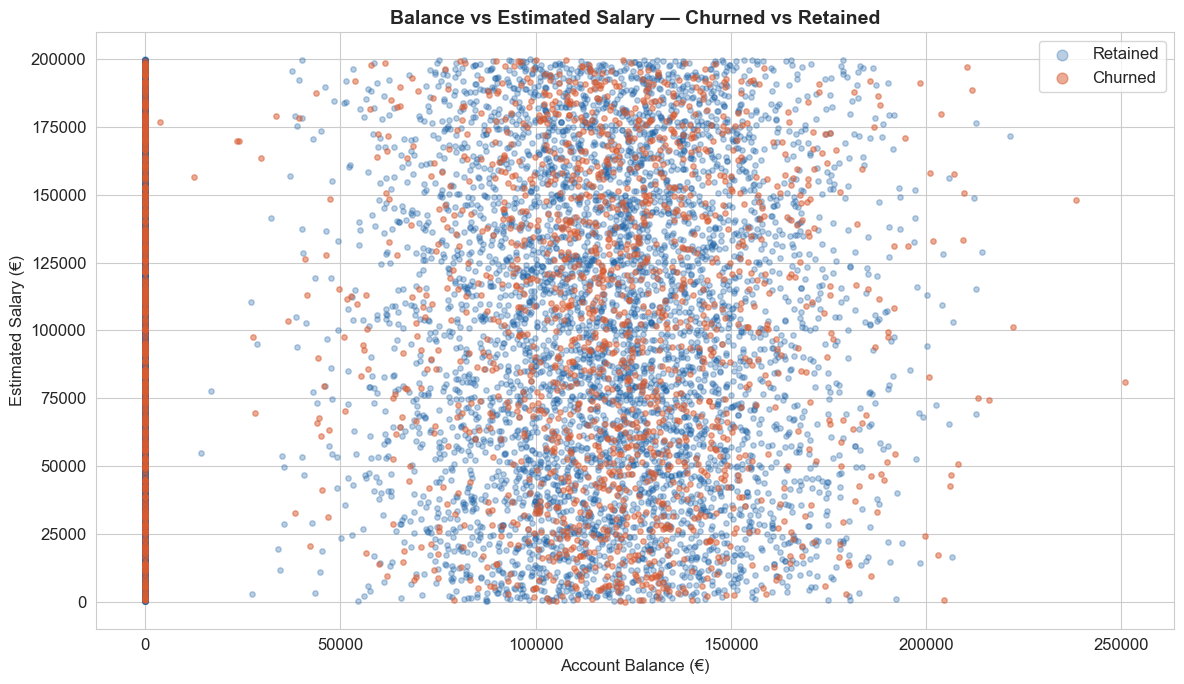


📌 Churned customers avg balance  : €91,109
   Churned customers avg salary   : €101,466
   Retained customers avg balance : €72,745
   Retained customers avg salary  : €99,738


In [9]:
# ── Chart 14: Balance vs Estimated Salary (Scatter) ───────────────
fig, ax = plt.subplots(figsize=(12, 7))

retained = df[df['Exited'] == 0]
churned  = df[df['Exited'] == 1]

ax.scatter(retained['Balance'], retained['EstimatedSalary'],
           alpha=0.3, color='#185FA5', label='Retained', s=15)
ax.scatter(churned['Balance'],  churned['EstimatedSalary'],
           alpha=0.5, color='#D85A30', label='Churned',  s=15)

ax.set_title('Balance vs Estimated Salary — Churned vs Retained',
             fontsize=14, fontweight='bold')
ax.set_xlabel('Account Balance (€)')
ax.set_ylabel('Estimated Salary (€)')
ax.legend(fontsize=12, markerscale=2)

plt.tight_layout()
plt.savefig('../reports/figures/14_balance_salary_scatter.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"\n📌 Churned customers avg balance  : €{churned['Balance'].mean():,.0f}")
print(f"   Churned customers avg salary   : €{churned['EstimatedSalary'].mean():,.0f}")
print(f"   Retained customers avg balance : €{retained['Balance'].mean():,.0f}")
print(f"   Retained customers avg salary  : €{retained['EstimatedSalary'].mean():,.0f}")

In [10]:
# ── Calculate All 5 KPIs ──────────────────────────────────────────
print("=" * 60)
print("       FINANCE ANALYTICS PROJECT — 5 KEY KPIs")
print("=" * 60)

# KPI 1: Overall Churn Rate
kpi1 = df['Exited'].mean() * 100
print(f"\n📌 KPI 1 — Overall Churn Rate    : {kpi1:.2f}%")

# KPI 2: Segment Churn Rate (Geography)
geo_rates = df.groupby('Geography')['Exited'].mean() * 100
print(f"\n📌 KPI 2 — Segment Churn Rates (Geography):")
for country, rate in geo_rates.items():
    print(f"   {country:<12} : {rate:.2f}%")

# KPI 3: High-Value Churn Ratio
hv_threshold = df['Balance'].quantile(0.75)
hv_customers = df[df['Balance'] >= hv_threshold]
kpi3 = hv_customers['Exited'].mean() * 100
print(f"\n📌 KPI 3 — High-Value Churn Ratio : {kpi3:.2f}%")
print(f"   (Customers with Balance ≥ €{hv_threshold:,.0f})")
print(f"   High-value customers who churned: {hv_customers['Exited'].sum()}")

# KPI 4: Geographic Risk Index
geo_risk = df.groupby('Geography')['Exited'].mean()
highest_risk = geo_risk.idxmax()
print(f"\n📌 KPI 4 — Geographic Risk Index:")
for c, r in geo_risk.items():
    flag = " ⚠️  HIGHEST RISK" if c == highest_risk else ""
    print(f"   {c:<12} : {r*100:.2f}%{flag}")

# KPI 5: Engagement Drop Indicator
inactive_churn = df[df['IsActiveMember']==0]['Exited'].mean() * 100
active_churn   = df[df['IsActiveMember']==1]['Exited'].mean() * 100
print(f"\n📌 KPI 5 — Engagement Drop Indicator:")
print(f"   Inactive members churn rate : {inactive_churn:.2f}%")
print(f"   Active members churn rate   : {active_churn:.2f}%")
print(f"   Difference                  : {inactive_churn - active_churn:.2f}%")

print("\n" + "=" * 60)
print("✅ All 5 KPIs Calculated Successfully!")
print("=" * 60)

       FINANCE ANALYTICS PROJECT — 5 KEY KPIs

📌 KPI 1 — Overall Churn Rate    : 20.37%

📌 KPI 2 — Segment Churn Rates (Geography):
   France       : 16.15%
   Germany      : 32.44%
   Spain        : 16.67%

📌 KPI 3 — High-Value Churn Ratio : 23.68%
   (Customers with Balance ≥ €127,644)
   High-value customers who churned: 592

📌 KPI 4 — Geographic Risk Index:
   France       : 16.15%
   Germany      : 32.44% ⚠️  HIGHEST RISK
   Spain        : 16.67%

📌 KPI 5 — Engagement Drop Indicator:
   Inactive members churn rate : 26.85%
   Active members churn rate   : 14.27%
   Difference                  : 12.58%

✅ All 5 KPIs Calculated Successfully!


In [11]:
# ── Save Final Scored Dataset ─────────────────────────────────────

# Add retention opportunity flag
hv_threshold = df['Balance'].quantile(0.75)
df['high_value_flag']        = (df['Balance'] >= hv_threshold).astype(int)
df['retention_opportunity']  = (
    (df['Exited'] == 0) &
    (df['IsActiveMember'] == 1) &
    (df['balance_segment'] == 'High Balance')
).astype(int)
df['churn_risk_flag'] = (
    (df['IsActiveMember'] == 0) &
    (df['NumOfProducts'] >= 3)
).astype(int)

# Save
save_path = '../data/processed/churn_final_scored.csv'
df.to_csv(save_path, index=False)

print(f"✅ Final scored dataset saved!")
print(f"   Path   : {save_path}")
print(f"   Shape  : {df.shape}")
print(f"\n📊 Summary Flags:")
print(f"   High-value customers        : {df['high_value_flag'].sum()}")
print(f"   Retention opportunities     : {df['retention_opportunity'].sum()}")
print(f"   High churn risk customers   : {df['churn_risk_flag'].sum()}")

✅ Final scored dataset saved!
   Path   : ../data/processed/churn_final_scored.csv
   Shape  : (10000, 19)

📊 Summary Flags:
   High-value customers        : 2500
   Retention opportunities     : 2089
   High churn risk customers   : 184


##  High-Value Customer Churn Analysis

In this section we identify customers with the highest account balances,
analyze their churn behavior, and quantify the revenue risk they represent.
High-value customers churning is especially dangerous for the bank because
they carry a disproportionate share of total deposits.

In [12]:
# ── High-Value Customer Identification ───────────────────────────────────────
# High-value = top 25% by account balance (above 75th percentile)

hv_threshold = df['Balance'].quantile(0.75)
hv_customers = df[df['Balance'] >= hv_threshold].copy()
lv_customers = df[df['Balance'] <  hv_threshold].copy()

print("=" * 60)
print("  HIGH-VALUE CUSTOMER ANALYSIS")
print("=" * 60)
print(f"\n  Balance threshold (75th percentile) : €{hv_threshold:,.2f}")
print(f"  High-value customers (total)        : {len(hv_customers):,}")
print(f"  High-value churned                  : {hv_customers['Exited'].sum():,}")
print(f"  High-value churn rate               : {hv_customers['Exited'].mean():.2%}")
print(f"\n  Low-value customers (total)         : {len(lv_customers):,}")
print(f"  Low-value churned                   : {lv_customers['Exited'].sum():,}")
print(f"  Low-value churn rate                : {lv_customers['Exited'].mean():.2%}")
print("=" * 60)

  HIGH-VALUE CUSTOMER ANALYSIS

  Balance threshold (75th percentile) : €127,644.24
  High-value customers (total)        : 2,500
  High-value churned                  : 592
  High-value churn rate               : 23.68%

  Low-value customers (total)         : 7,500
  Low-value churned                   : 1,445
  Low-value churn rate                : 19.27%


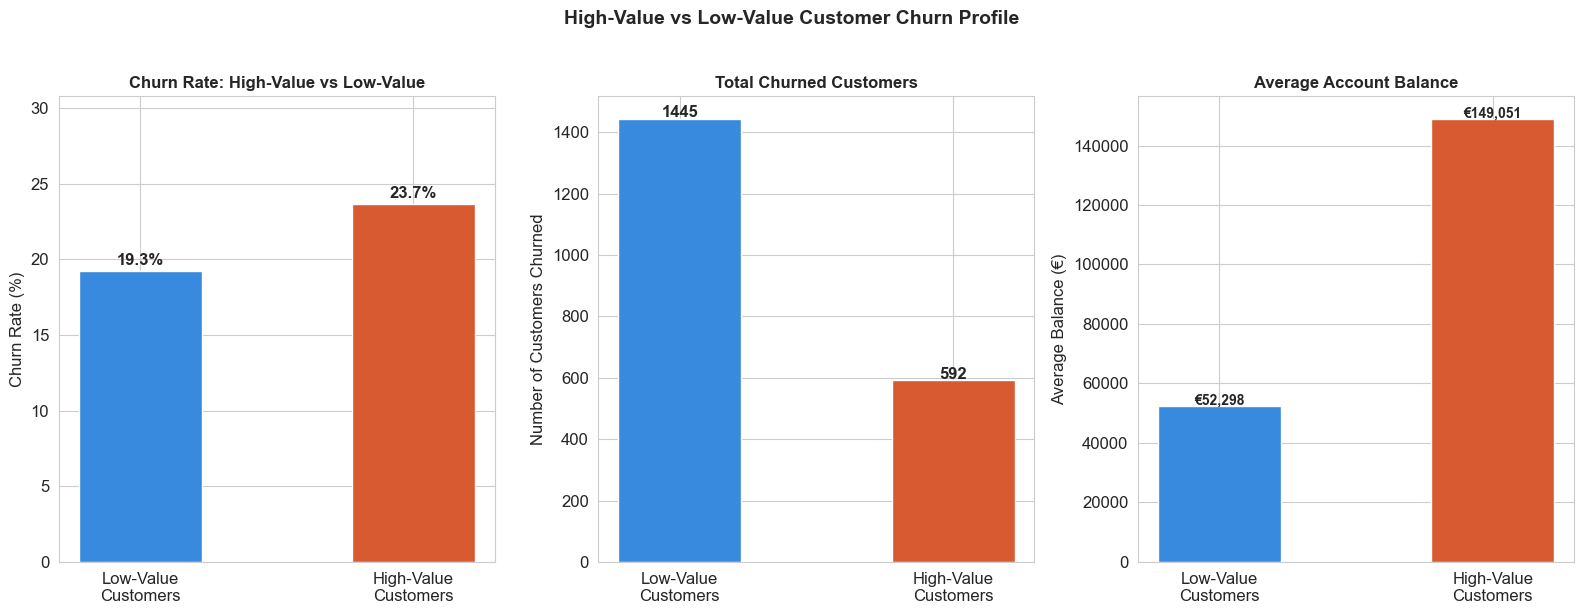

In [13]:
# ── Chart 15: High-Value vs Low-Value Churn Rate Comparison ──────────────────
fig, axes = plt.subplots(1, 3, figsize=(16, 6))

segments    = ['Low-Value\nCustomers', 'High-Value\nCustomers']
churn_rates = [lv_customers['Exited'].mean() * 100,
               hv_customers['Exited'].mean() * 100]
counts      = [lv_customers['Exited'].sum(), hv_customers['Exited'].sum()]
colors      = ['#378ADD', '#D85A30']

# Chart A: Churn Rate Comparison
bars = axes[0].bar(segments, churn_rates, color=colors, width=0.45, edgecolor='white')
axes[0].set_title('Churn Rate: High-Value vs Low-Value', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Churn Rate (%)')
axes[0].set_ylim(0, max(churn_rates) * 1.3)
for bar, val in zip(bars, churn_rates):
    axes[0].text(bar.get_x() + bar.get_width() / 2,
                 bar.get_height() + 0.4,
                 f"{val:.1f}%", ha='center', fontsize=12, fontweight='bold')

# Chart B: Total Churned Count
bars2 = axes[1].bar(segments, counts, color=colors, width=0.45, edgecolor='white')
axes[1].set_title('Total Churned Customers', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Number of Customers Churned')
for bar, val in zip(bars2, counts):
    axes[1].text(bar.get_x() + bar.get_width() / 2,
                 bar.get_height() + 5,
                 str(val), ha='center', fontsize=12, fontweight='bold')

# Chart C: Average Balance comparison
avg_balances = [lv_customers['Balance'].mean(), hv_customers['Balance'].mean()]
bars3 = axes[2].bar(segments, avg_balances, color=colors, width=0.45, edgecolor='white')
axes[2].set_title('Average Account Balance', fontsize=12, fontweight='bold')
axes[2].set_ylabel('Average Balance (€)')
for bar, val in zip(bars3, avg_balances):
    axes[2].text(bar.get_x() + bar.get_width() / 2,
                 bar.get_height() + 500,
                 f"€{val:,.0f}", ha='center', fontsize=10, fontweight='bold')

plt.suptitle('High-Value vs Low-Value Customer Churn Profile',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('../reports/figures/15_highvalue_vs_lowvalue.png', dpi=150, bbox_inches='tight')
plt.show()

  REVENUE AT RISK ANALYSIS

  Total bank deposits              : €    764,858,893
  Balance held by churned customers: €    185,588,095
  % of deposits at risk            : 24.3%

  High-value churned balance       : €     88,654,932
  Avg balance per churned customer : €         91,109
  Avg balance per retained customer: €         72,745


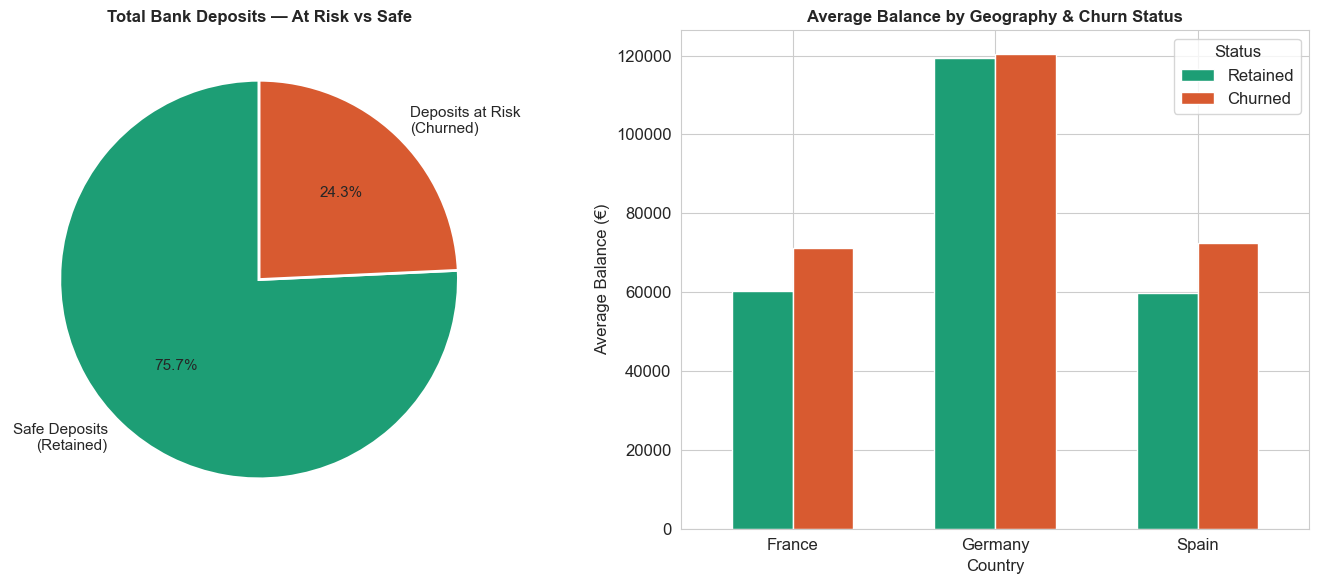

In [14]:
# ── Chart 16: Revenue at Risk Quantification ─────────────────────────────────
# Revenue at risk = total balance held by churned customers

churned_df   = df[df['Exited'] == 1]
retained_df  = df[df['Exited'] == 0]

total_balance_at_risk    = churned_df['Balance'].sum()
hv_balance_at_risk       = hv_customers[hv_customers['Exited'] == 1]['Balance'].sum()
total_deposits           = df['Balance'].sum()
pct_deposits_at_risk     = (total_balance_at_risk / total_deposits * 100) if total_deposits > 0 else 0

print("=" * 60)
print("  REVENUE AT RISK ANALYSIS")
print("=" * 60)
print(f"\n  Total bank deposits              : €{total_deposits:>15,.0f}")
print(f"  Balance held by churned customers: €{total_balance_at_risk:>15,.0f}")
print(f"  % of deposits at risk            : {pct_deposits_at_risk:.1f}%")
print(f"\n  High-value churned balance       : €{hv_balance_at_risk:>15,.0f}")
print(f"  Avg balance per churned customer : €{churned_df['Balance'].mean():>15,.0f}")
print(f"  Avg balance per retained customer: €{retained_df['Balance'].mean():>15,.0f}")
print("=" * 60)

# Bar chart
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Deposits at risk breakdown
risk_labels = ['Safe Deposits\n(Retained)', 'Deposits at Risk\n(Churned)']
risk_values = [total_deposits - total_balance_at_risk, total_balance_at_risk]
risk_colors = ['#1D9E75', '#D85A30']

wedges, texts, autotexts = axes[0].pie(
    risk_values, labels=risk_labels, colors=risk_colors,
    autopct='%1.1f%%', startangle=90,
    textprops={'fontsize': 11},
    wedgeprops={'edgecolor': 'white', 'linewidth': 2}
)
axes[0].set_title('Total Bank Deposits — At Risk vs Safe', fontsize=12, fontweight='bold')

# Avg balance churned vs retained by geography
geo_avg = df.groupby(['Geography', 'Exited'])['Balance'].mean().unstack()
geo_avg.columns = ['Retained', 'Churned']
geo_avg.plot(kind='bar', ax=axes[1], color=['#1D9E75', '#D85A30'],
             edgecolor='white', width=0.6)
axes[1].set_title('Average Balance by Geography & Churn Status', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Average Balance (€)')
axes[1].set_xlabel('Country')
axes[1].legend(title='Status')
axes[1].tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.savefig('../reports/figures/16_revenue_at_risk.png', dpi=150, bbox_inches='tight')
plt.show()

  GEOGRAPHIC RISK INDEX
Geography  Customers  Churned  Churn Rate %  Balance at Risk (€)  Risk Index (0-100)
   France       5014      810     16.154767          57666164.54                49.8
  Germany       2509      814     32.443204          97973915.53               100.0
    Spain       2477      413     16.673395          29948014.56                51.4


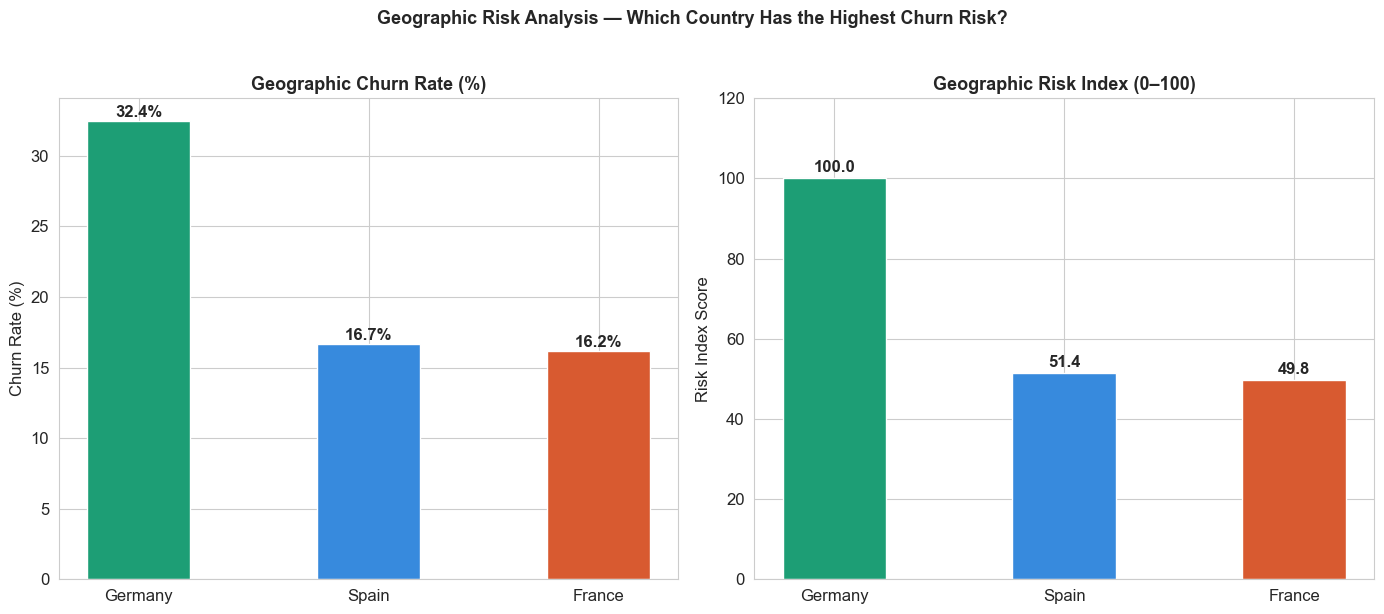

In [15]:
# ── Chart 17: Geographic Risk Index ──────────────────────────────────────────
geo_risk = df.groupby('Geography').agg(
    total_customers  = ('Exited', 'count'),
    total_churned    = ('Exited', 'sum'),
    churn_rate       = ('Exited', 'mean'),
    avg_balance      = ('Balance', 'mean'),
    total_balance    = ('Balance', 'sum')
).reset_index()

geo_risk['churn_rate_pct']    = geo_risk['churn_rate'] * 100
geo_risk['balance_at_risk']   = geo_risk.apply(
    lambda r: df[(df['Geography'] == r['Geography']) &
                 (df['Exited'] == 1)]['Balance'].sum(), axis=1
)
geo_risk['risk_index'] = (
    geo_risk['churn_rate_pct'] / geo_risk['churn_rate_pct'].max() * 100
).round(1)

print("=" * 60)
print("  GEOGRAPHIC RISK INDEX")
print("=" * 60)
print(geo_risk[['Geography','total_customers','total_churned',
                'churn_rate_pct','balance_at_risk','risk_index']]\
      .rename(columns={
          'total_customers' : 'Customers',
          'total_churned'   : 'Churned',
          'churn_rate_pct'  : 'Churn Rate %',
          'balance_at_risk' : 'Balance at Risk (€)',
          'risk_index'      : 'Risk Index (0-100)'
      }).to_string(index=False))
print("=" * 60)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
colors_geo = ['#1D9E75', '#378ADD', '#D85A30']
sorted_geo = geo_risk.sort_values('churn_rate_pct', ascending=False)

# Churn rate bar
bars = axes[0].bar(sorted_geo['Geography'], sorted_geo['churn_rate_pct'],
                   color=colors_geo, width=0.45, edgecolor='white')
axes[0].set_title('Geographic Churn Rate (%)', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Churn Rate (%)')
for bar, val in zip(bars, sorted_geo['churn_rate_pct']):
    axes[0].text(bar.get_x() + bar.get_width() / 2,
                 bar.get_height() + 0.3,
                 f"{val:.1f}%", ha='center', fontsize=12, fontweight='bold')

# Risk index bar
bars2 = axes[1].bar(sorted_geo['Geography'], sorted_geo['risk_index'],
                    color=colors_geo, width=0.45, edgecolor='white')
axes[1].set_title('Geographic Risk Index (0–100)', fontsize=13, fontweight='bold')
axes[1].set_ylabel('Risk Index Score')
axes[1].set_ylim(0, 120)
for bar, val in zip(bars2, sorted_geo['risk_index']):
    axes[1].text(bar.get_x() + bar.get_width() / 2,
                 bar.get_height() + 1.5,
                 str(val), ha='center', fontsize=12, fontweight='bold')

plt.suptitle('Geographic Risk Analysis — Which Country Has the Highest Churn Risk?',
             fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('../reports/figures/17_geographic_risk_index.png', dpi=150, bbox_inches='tight')
plt.show()

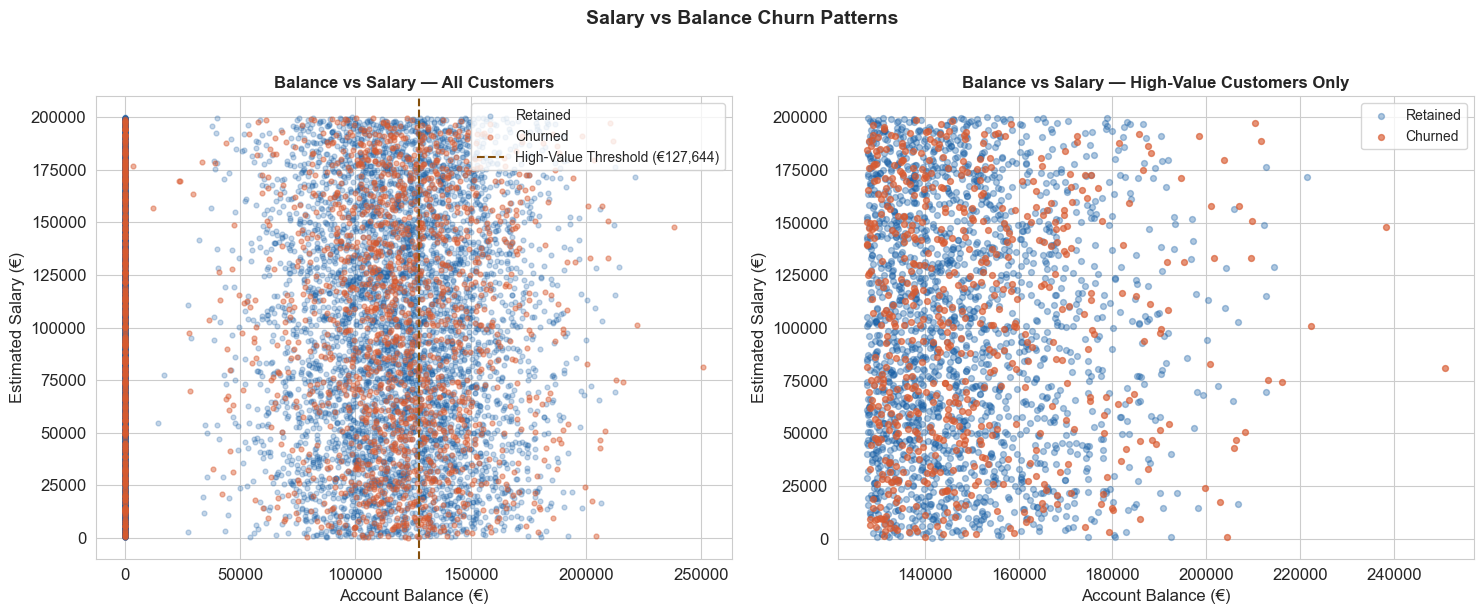

In [16]:
# ── Chart 18: Salary vs Balance — High-Value Customer Deep Dive ──────────────
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# All customers scatter
axes[0].scatter(
    retained_df['Balance'], retained_df['EstimatedSalary'],
    alpha=0.25, color='#185FA5', label='Retained', s=12
)
axes[0].scatter(
    churned_df['Balance'], churned_df['EstimatedSalary'],
    alpha=0.45, color='#D85A30', label='Churned', s=12
)
axes[0].axvline(x=hv_threshold, color='#854F0B', linewidth=1.5,
                linestyle='--', label=f'High-Value Threshold (€{hv_threshold:,.0f})')
axes[0].set_title('Balance vs Salary — All Customers', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Account Balance (€)')
axes[0].set_ylabel('Estimated Salary (€)')
axes[0].legend(fontsize=10)

# High-value customers only
hv_retained = hv_customers[hv_customers['Exited'] == 0]
hv_churned  = hv_customers[hv_customers['Exited'] == 1]

axes[1].scatter(
    hv_retained['Balance'], hv_retained['EstimatedSalary'],
    alpha=0.35, color='#185FA5', label='Retained', s=18
)
axes[1].scatter(
    hv_churned['Balance'], hv_churned['EstimatedSalary'],
    alpha=0.65, color='#D85A30', label='Churned', s=18
)
axes[1].set_title('Balance vs Salary — High-Value Customers Only', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Account Balance (€)')
axes[1].set_ylabel('Estimated Salary (€)')
axes[1].legend(fontsize=10)

plt.suptitle('Salary vs Balance Churn Patterns', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('../reports/figures/18_salary_balance_highvalue.png', dpi=150, bbox_inches='tight')
plt.show()

## All KPIs Compiled + Final Dataset Saved

Here we consolidate all 5 project KPIs into a single summary,
add risk flags to each customer record, and save the final
dataset that will power the Streamlit dashboard.

In [17]:
# ── KPI MASTER SUMMARY TABLE ──────────────────────────────────────────────────

hv_threshold  = df['Balance'].quantile(0.75)
hv_df         = df[df['Balance'] >= hv_threshold]
inactive_df   = df[df['IsActiveMember'] == 0]
active_df     = df[df['IsActiveMember'] == 1]
geo_churn_map = df.groupby('Geography')['Exited'].mean() * 100

kpi_results = {
    'KPI 1 — Overall Churn Rate'    : f"{df['Exited'].mean() * 100:.2f}%",
    'KPI 2 — Segment Churn (France)': f"{geo_churn_map.get('France', 0):.2f}%",
    'KPI 2 — Segment Churn (Germany)':f"{geo_churn_map.get('Germany', 0):.2f}%",
    'KPI 2 — Segment Churn (Spain)' : f"{geo_churn_map.get('Spain', 0):.2f}%",
    'KPI 3 — High-Value Churn Ratio': f"{hv_df['Exited'].mean() * 100:.2f}%",
    'KPI 4 — Highest Risk Country'  : geo_churn_map.idxmax(),
    'KPI 4 — Risk Index Score'      : f"{geo_churn_map.max():.2f}%",
    'KPI 5 — Inactive Member Churn' : f"{inactive_df['Exited'].mean() * 100:.2f}%",
    'KPI 5 — Active Member Churn'   : f"{active_df['Exited'].mean() * 100:.2f}%",
    'KPI 5 — Engagement Gap'        : f"{(inactive_df['Exited'].mean() - active_df['Exited'].mean()) * 100:.2f}%",
}

print("=" * 62)
print("        FINANCE ANALYTICS PROJECT — MASTER KPI REPORT")
print("=" * 62)
for kpi, value in kpi_results.items():
    print(f"  {kpi:<40} {value}")
print("=" * 62)

        FINANCE ANALYTICS PROJECT — MASTER KPI REPORT
  KPI 1 — Overall Churn Rate               20.37%
  KPI 2 — Segment Churn (France)           16.15%
  KPI 2 — Segment Churn (Germany)          32.44%
  KPI 2 — Segment Churn (Spain)            16.67%
  KPI 3 — High-Value Churn Ratio           23.68%
  KPI 4 — Highest Risk Country             Germany
  KPI 4 — Risk Index Score                 32.44%
  KPI 5 — Inactive Member Churn            26.85%
  KPI 5 — Active Member Churn              14.27%
  KPI 5 — Engagement Gap                   12.58%


In [18]:
# ── Build Final Scored Dataset ────────────────────────────────────────────────
hv_threshold = df['Balance'].quantile(0.75)

# Flag 1: High-value customer
df['high_value_flag'] = (df['Balance'] >= hv_threshold).astype(int)

# Flag 2: Retention opportunity — still with bank, active, but in a high-risk profile
#         (high balance + inactive OR high balance + 3+ products)
df['retention_opportunity'] = (
    (df['Exited'] == 0) &
    (df['Balance'] >= hv_threshold) &
    ((df['IsActiveMember'] == 0) | (df['NumOfProducts'] >= 3))
).astype(int)

# Flag 3: High churn risk — inactive member with 3+ products
df['high_churn_risk'] = (
    (df['IsActiveMember'] == 0) &
    (df['NumOfProducts'] >= 3)
).astype(int)

# Flag 4: Engagement drop indicator
df['engagement_drop'] = (df['IsActiveMember'] == 0).astype(int)

save_path = '../data/processed/churn_final_scored.csv'
df.to_csv(save_path, index=False)

print("Final dataset saved successfully!")
print(f"  Path            : {save_path}")
print(f"  Shape           : {df.shape}")
print(f"  Total columns   : {df.columns.tolist()}")
print(f"\n  Summary flags:")
print(f"  High-value customers      : {df['high_value_flag'].sum():,}")
print(f"  Retention opportunities   : {df['retention_opportunity'].sum():,}")
print(f"  High churn risk customers : {df['high_churn_risk'].sum():,}")
print(f"  Engagement drop customers : {df['engagement_drop'].sum():,}")

Final dataset saved successfully!
  Path            : ../data/processed/churn_final_scored.csv
  Shape           : (10000, 21)
  Total columns   : ['CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Exited', 'age_segment', 'credit_band', 'tenure_group', 'balance_segment', 'products_segment', 'high_value_flag', 'retention_opportunity', 'churn_risk_flag', 'high_churn_risk', 'engagement_drop']

  Summary flags:
  High-value customers      : 2,500
  Retention opportunities   : 870
  High churn risk customers : 184
  Engagement drop customers : 4,849


In [21]:
# ──Completion Verification ────────────────────────────────────────
import os

figures_path = '../reports/figures/'
saved_figures = sorted([f for f in os.listdir(figures_path) if f.endswith('.png')])

print("=" * 55)
print(" compelete")
print("=" * 55)
print(f"\n  Figures saved ({len(saved_figures)} total):")
for fig in saved_figures:
    print(f"    {fig}")

data_files = os.listdir('../data/processed/')
print(f"\n  Processed data files:")
for f in data_files:
    print(f"    {f}")


print("=" * 55)

 compelete

  Figures saved (18 total):
    01_overall_churn.png
    02_geography_churn.png
    03_gender_churn.png
    04_age_distribution.png
    05_balance_distribution.png
    06_correlation_heatmap.png
    07_age_segment_churn.png
    08_credit_band_churn.png
    09_tenure_churn.png
    10_geo_age_heatmap.png
    11_gender_geo_churn.png
    12_active_member_churn.png
    13_products_churn.png
    14_balance_salary_scatter.png
    15_highvalue_vs_lowvalue.png
    16_revenue_at_risk.png
    17_geographic_risk_index.png
    18_salary_balance_highvalue.png

  Processed data files:
    churn_final_scored.csv
    churn_segmented.csv


## 📌 Conclusion & Transition to Machine Learning

Through segmentation and KPI analysis, we isolated key risk cohorts:
- **Geography**: German accounts exhibit 2x the churn rate of French/Spanish peers.
- **Age Segment**: Customers aged 46–60 exhibit ~56% churn rate.
- **Products**: Customers with 3+ products churn at >80%.
- **Engagement Gap**: Inactive accounts have significantly higher churn across all brackets.

➡️ **Next Step**: Open `03_ml_churn_prediction_modeling.ipynb` to build, tune, and evaluate predictive machine learning models (XGBoost, Random Forest, Logistic Regression) and export production pipelines for live inference.